# 🧠 Modèle CNN — Détection de places de parking

Dans cette partie, on construit un **réseau de neurones convolutionnel (CNN)** pour classifier chaque place de parking en **libre** ou **occupée** à partir d'une image recadrée.

**Architecture implémentée :**
1. Convolution + filtre  →  extraction des features
2. ReLU  →  activation non-linéaire
3. Max Pooling  →  réduction de dimension
4. Flatten  →  mise à plat en vecteur 1D
5. Fully Connected 1 + ReLU  →  combinaison des features
6. Fully Connected 2 + Softmax  →  probabilités de classe


## Importation des bibliothèques

- `tensorflow.keras` : construction et entraînement du CNN
- `sklearn` : découpage train/test
- `matplotlib` : courbes d'apprentissage


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split

# Taille standard des images en entrée du réseau
IMG_WIDTH  = 64
IMG_HEIGHT = 64
CHANNELS   = 3   # RGB


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

---
## 1. Chargement du dataset

Le dataset doit être organisé en deux sous-dossiers :
```
dataset/
├── libre/      ← images de places libres
└── occupee/    ← images de places occupées
```
Chaque image est chargée, redimensionnée en 64×64, et normalisée entre 0 et 1.


In [3]:
DATASET_DIR = './data'                # dossier contenant les deux classes
CLASSES     = ['empty', 'parked']   # 0 = libre, 1 = occupée

X = []   # liste des images
y = []   # liste des étiquettes

for label, class_name in enumerate(CLASSES):
    class_dir = os.path.join(DATASET_DIR, class_name)
    for filename in os.listdir(class_dir):
        if filename.endswith(('.jpg', '.png', '.jpeg')):
            img_path = os.path.join(class_dir, filename)
            # Charger et redimensionner l'image à 64×64 pixels
            img = load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
            # Convertir en tableau numpy et normaliser entre 0 et 1
            img_array = img_to_array(img) / 255.0
            X.append(img_array)
            y.append(label)

X = np.array(X)   # shape : (nb_images, 64, 64, 3)
y = np.array(y)

print(f'Dataset chargé : {len(X)} images')
print(f'  Libres    : {np.sum(y == 0)}')
print(f'  Occupées  : {np.sum(y == 1)}')


Dataset chargé : 813 images
  Libres    : 192
  Occupées  : 621


---
## 2. Préparation des données

On encode les étiquettes en **vecteurs one-hot** (ex: libre → [1,0], occupée → [0,1]) et on divise les données en 80 % entraînement / 20 % test.


In [4]:
# Encoder les étiquettes : libre=[1,0]  occupée=[0,1]
y_onehot = to_categorical(y, num_classes=2)

# Découper : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot, test_size=0.2, random_state=42
)

print(f'Entraînement : {len(X_train)} images')
print(f'Test         : {len(X_test)} images')


Entraînement : 650 images
Test         : 163 images


---
## 3. Construction du modèle CNN

On empile les couches dans l'ordre suivant :


### 3.1 Convolution + ReLU

La couche `Conv2D` applique **32 filtres 3×3** qui glissent sur l'image. Chaque filtre apprend à détecter un pattern différent (contour vertical, horizontal, texture, etc.).

**ReLU** (`max(0, x)`) est appliqué directement via `activation='relu'` : il supprime toutes les valeurs négatives et introduit la non-linéarité nécessaire.


### 3.2 Max Pooling

`MaxPooling2D(2, 2)` divise la résolution par 2 en gardant la valeur maximale de chaque fenêtre 2×2. Cela réduit le nombre de paramètres et rend le modèle moins sensible aux petits décalages.


### 3.3 Flatten

La sortie du pooling est une matrice 3D (hauteur × largeur × filtres). `Flatten` la transforme en un vecteur 1D pour pouvoir la passer aux couches Dense.


### 3.4 Fully Connected + Softmax

Deux couches `Dense` combinent toutes les features :
- **FC1 (128 neurones + ReLU)** : apprend des combinaisons complexes
- **FC2 (2 neurones + Softmax)** : produit deux probabilités qui somment à 1

Softmax convertit les scores bruts en probabilités : `[0.9, 0.1]` = 90 % libre, 10 % occupée.


In [5]:
model = Sequential([

    # ── Convolution + ReLU ──
    # 32 filtres 3×3 extraient les features de l'image
    # activation='relu' applique max(0,x) sur chaque valeur
    Conv2D(filters=32, kernel_size=(3, 3), padding='same',
           activation='relu',
           input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),

    # ── Max Pooling ──
    # Fenêtre 2×2 : divise la résolution par 2, garde les valeurs max
    MaxPooling2D(pool_size=(2, 2)),

    # ── Flatten ──
    # Aplatit la carte de features 3D en un vecteur 1D
    Flatten(),

    # ── Fully Connected 1 + ReLU ──
    # 128 neurones combinent les features extraites
    Dense(units=128, activation='relu'),

    # ── Fully Connected 2 + Softmax ──
    # 2 neurones = 2 classes : Softmax donne des probabilités (somme = 1)
    Dense(units=2, activation='softmax'),

])

model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 32)        0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 32768)             0         
                                                                 
 dense (Dense)               (None, 128)               4194432   
                                                                 
 dense_1 (Dense)             (None, 2)                 258       
                                                                 
Total params: 4195586 (16.00 MB)
Trainable params: 4195586 (16.00 MB)
Non-trainable params: 0 (0.00 Byte)
______________

---
## 4. Compilation et entraînement

On compile avec l'optimiseur **Adam** (ajuste les poids automatiquement) et la fonction de perte **categorical crossentropy** (adaptée à la classification multi-classes).


In [6]:
# Compiler le modèle
model.compile(
    optimizer='adam',                   # optimiseur adaptatif
    loss='categorical_crossentropy',    # perte pour classification multi-classes
    metrics=['accuracy']                # suivre la précision pendant l'entraînement
)

# Entraîner le modèle
history = model.fit(
    X_train, y_train,
    epochs=15,            # nombre de passages complets sur les données
    batch_size=32,        # images traitées à la fois
    validation_split=0.1  # 10 % des données train pour surveiller le surapprentissage
)


Epoch 1/15


19/19 [==============================] - 3s 95ms/step - loss: 0.9629 - accuracy: 0.7265 - val_loss: 0.4206 - val_accuracy: 0.7538
Epoch 2/15
19/19 [==============================] - 1s 71ms/step - loss: 0.3293 - accuracy: 0.8017 - val_loss: 0.2674 - val_accuracy: 0.9692
Epoch 3/15
19/19 [==============================] - 1s 77ms/step - loss: 0.2463 - accuracy: 0.9128 - val_loss: 0.2054 - val_accuracy: 0.9385
Epoch 4/15
19/19 [==============================] - 1s 70ms/step - loss: 0.1983 - accuracy: 0.9538 - val_loss: 0.1988 - val_accuracy: 0.9538
Epoch 5/15
19/19 [==============================] - 1s 72ms/step - loss: 0.1811 - accuracy: 0.9744 - val_loss: 0.2025 - val_accuracy: 0.9538
Epoch 6/15
19/19 [==============================] - 1s 66ms/step - loss: 0.1726 - accuracy: 0.9761 - val_loss: 0.1864 - val_accuracy: 0.9692
Epoch 7/15
19/19 [==============================] - 1s 80ms/step - loss: 0.1763 - accuracy: 0.9744 - val_loss: 0.1923 - val_accuracy: 0.9538
Epoch 8/15


---
## 5. Évaluation et courbes d'apprentissage

On évalue le modèle sur le jeu de test (jamais vu pendant l'entraînement), puis on trace les courbes d'accuracy et de loss pour vérifier l'apprentissage.


Précision sur le test : 98.2 %


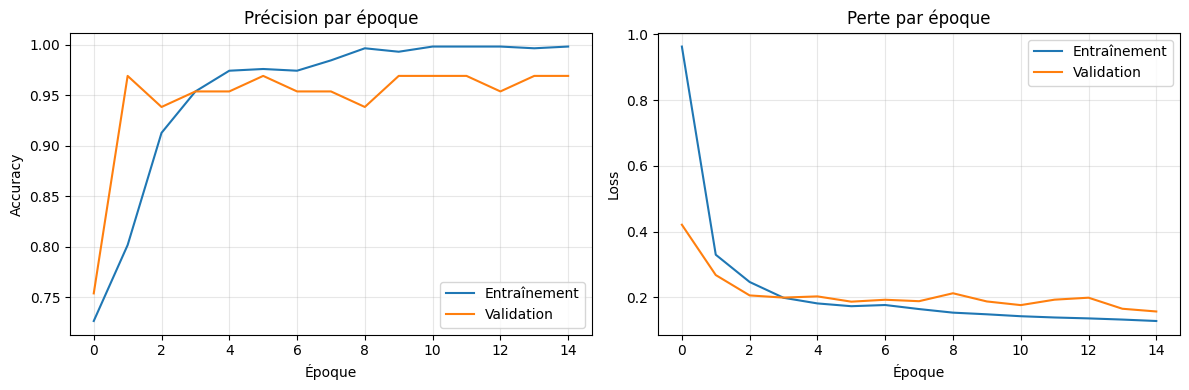

In [7]:
# Évaluation sur les données de test
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Précision sur le test : {test_acc*100:.1f} %')

# Tracer les courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Courbe de précision
ax1.plot(history.history['accuracy'],     label='Entraînement')
ax1.plot(history.history['val_accuracy'], label='Validation')
ax1.set_title('Précision par époque')
ax1.set_xlabel('Époque')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Courbe de perte
ax2.plot(history.history['loss'],     label='Entraînement')
ax2.plot(history.history['val_loss'], label='Validation')
ax2.set_title('Perte par époque')
ax2.set_xlabel('Époque')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 6. Sauvegarde et prédiction

On sauvegarde le modèle entraîné, puis on crée une fonction qui prend **une image de place** et retourne si elle est libre ou occupée avec les probabilités associées.


In [8]:
# Sauvegarder le modèle pour le réutiliser sans ré-entraîner
model.save('cnn_parking.keras')
print('Modèle sauvegardé dans cnn_parking.keras')

def predire_place(chemin_image, modele):
    """
    Prend le chemin d'une image de place de parking
    et retourne si elle est libre (0) ou occupée (1).
    """
    # Charger et préparer l'image comme pendant l'entraînement
    img = load_img(chemin_image, target_size=(IMG_HEIGHT, IMG_WIDTH))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)  # ajouter dimension batch

    # Prédiction : [probabilité libre, probabilité occupée]
    prediction = modele.predict(img_array, verbose=0)[0]
    classe = np.argmax(prediction)  # classe avec la probabilité la plus haute

    print(f'Probabilité libre    : {prediction[0]*100:.1f} %')
    print(f'Probabilité occupée  : {prediction[1]*100:.1f} %')
    print(f'Résultat             : {"🟢 LIBRE" if classe == 0 else "🔴 OCCUPÉE"}')
    return classe

# Exemple d'utilisation :
# predire_place('ma_place.jpg', model)


Modèle sauvegardé dans cnn_parking.keras


---
## 7. Intégration CNN sur l'image complète

Une fois le modèle CNN entraîné, on l'intègre dans le pipeline de détection original.
L'idée est simple : pour chaque place de parking définie manuellement (ROI),
on **découpe la zone**, on la passe dans le CNN, et on utilise la **sortie Softmax**
pour colorier la place en vert (libre) ou rouge (occupée).

In [5]:
from tensorflow.keras.models import load_model
import numpy as np
import cv2
import pickle

In [9]:
# Recharger les positions sauvegardées depuis le fichier
with open("../Traditionnel/positions.pkl", "rb") as f:
    positions = pickle.load(f)

# Charger le modèle entraîné
model = load_model('cnn_parking.keras')

In [6]:
img = cv2.imread('../Traditionnel/parking.jpg')
img_resized = cv2.resize(img, (1280, 720))


In [10]:

img_affichage = img_resized.copy()
libres   = 0
occupees = 0

for (x, y, w, h) in positions:
    # Découper la ROI
    roi = img_resized[y:y+h, x:x+w]

    # Préparer pour le CNN : redimensionner + normaliser
    roi_resized = cv2.resize(roi, (64, 64))
    roi_rgb     = cv2.cvtColor(roi_resized, cv2.COLOR_BGR2RGB)
    roi_input   = roi_rgb.astype('float32') / 255.0
    roi_input   = np.expand_dims(roi_input, axis=0)  # shape (1, 64, 64, 3)

    # Prédiction CNN
    prediction = model.predict(roi_input, verbose=0)[0]
    classe = np.argmax(prediction)  # 0=empty, 1=parked

    if classe == 0:
        couleur = (0, 255, 0)   # vert = libre
        libres += 1
    else:
        couleur = (0, 0, 255)   # rouge = occupée
        occupees += 1

    # Dessiner le rectangle + probabilité
    cv2.rectangle(img_affichage, (x, y), (x+w, y+h), couleur, 2)
    label = f"{prediction[classe]*100:.0f}%"
    cv2.putText(img_affichage, label, (x+4, y+18),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, couleur, 1)

# Résumé en haut de l'image
cv2.putText(img_affichage, f"Libres: {libres}  Occupees: {occupees}",
            (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 0), 2)

cv2.imshow("Résultat CNN", img_affichage)
cv2.waitKey(0)
cv2.destroyAllWindows()